<a href="https://colab.research.google.com/github/RizkiHadiono/244107020198-Pembelajaran-Mesin/blob/main/JS15_244107020198_MOKHAMAD_RIZKI_HADIONO_SINGGIH.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS15 - Pipeline Machine Learning dan Deployment

**Nama:** Mokhamad Rizki Hadiono Singgih  
**NIM:** 244107020198

Praktikum 1 klasifikasi Day vs Night dengan HOG dan Neural Network, Praktikum 2 deployment Flask dan Docker ke Hugging Face Spaces, serta tugas penerapan pipeline yang sama pada model project sendiri.

# Praktikum 1 - Klasifikasi Day vs Night

## Langkah 1: Import Library

Pustaka yang dipakai untuk pengolahan citra, ekstraksi fitur, dan pelatihan model. Pada jobsheet, sel ini ditutup dengan `drive.mount('/content/drive')` untuk membaca dataset dari Google Drive. Dataset di sini sudah berada di folder kerja, jadi mount tidak diperlukan dan path dibaca relatif terhadap folder tersebut.

In [ ]:
%matplotlib inline

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import cv2

from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models

np.random.seed(42)
tf.keras.utils.set_random_seed(42)

## Langkah 2: Load Dataset

Dataset berisi folder `images/training` dan `images/test`, masing-masing punya subfolder `day` dan `night`. Sel berikut mengekstrak `images.zip` kalau folder `images` belum ada, lalu menghitung jumlah gambar per kelas.

In [ ]:
import zipfile

if not Path('images/training').exists():
    with zipfile.ZipFile('images.zip') as z:
        for anggota in z.namelist():
            if anggota.startswith('__MACOSX') or anggota.endswith('/'):
                continue
            z.extract(anggota, '.')

for bagian in ['training', 'test']:
    for kelas in ['day', 'night']:
        jumlah = len(list(Path(f'images/{bagian}/{kelas}').glob('*.jpg')))
        print(f'{bagian:8s} {kelas:5s} : {jumlah} gambar')

training day   : 120 gambar
training night : 120 gambar
test     day   : 80 gambar
test     night : 80 gambar


In [ ]:
# Load images and labels from a directory structure
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []
    for folder in p.glob('*'):
        label = folder.name
        for file in folder.glob('*.jpg'):
            img = cv2.imread(str(file))
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img_list.append((img, label))
    return img_list

train_dir = 'images/training'
test_dir  = 'images/test'

train_img = load_dataset(train_dir)
test_img  = load_dataset(test_dir)

print(f"Jumlah data training: {len(train_img)}")
print(f"Jumlah data testing: {len(test_img)}")

Jumlah data training: 240
Jumlah data testing: 160


## Langkah 3: Preprocessing (Resize dan Label Encoding)

Ukuran gambar diseragamkan menjadi 256 x 256 karena HOG membutuhkan dimensi tetap, sedangkan gambar aslinya berbeda-beda. Label teks diubah menjadi angka biner, `day` menjadi 1 dan `night` menjadi 0.

In [ ]:
# Preprocess images: resize and encode labels
def resize_image(img, size=(256,256)):
    return cv2.resize(img, size)

def label_encoder(label):
    return 1 if label == 'day' else 0

def preprocess(img_list):
    X = []
    y = []
    for img, label in img_list:
        img_std = resize_image(img)
        X.append(img_std)
        y.append(label_encoder(label))
    return X, y

X_train_img, y_train = preprocess(train_img)
X_test_img,  y_test  = preprocess(test_img)

print('Jumlah citra latih :', len(X_train_img))
print('Jumlah citra uji   :', len(X_test_img))
print('Ukuran satu citra  :', X_train_img[0].shape)
print('Sebaran label latih:', np.bincount(y_train))
print('Sebaran label uji  :', np.bincount(y_test))

Jumlah citra latih : 240
Jumlah citra uji   : 160
Ukuran satu citra  : (256, 256, 3)
Sebaran label latih: [120 120]
Sebaran label uji  : [80 80]


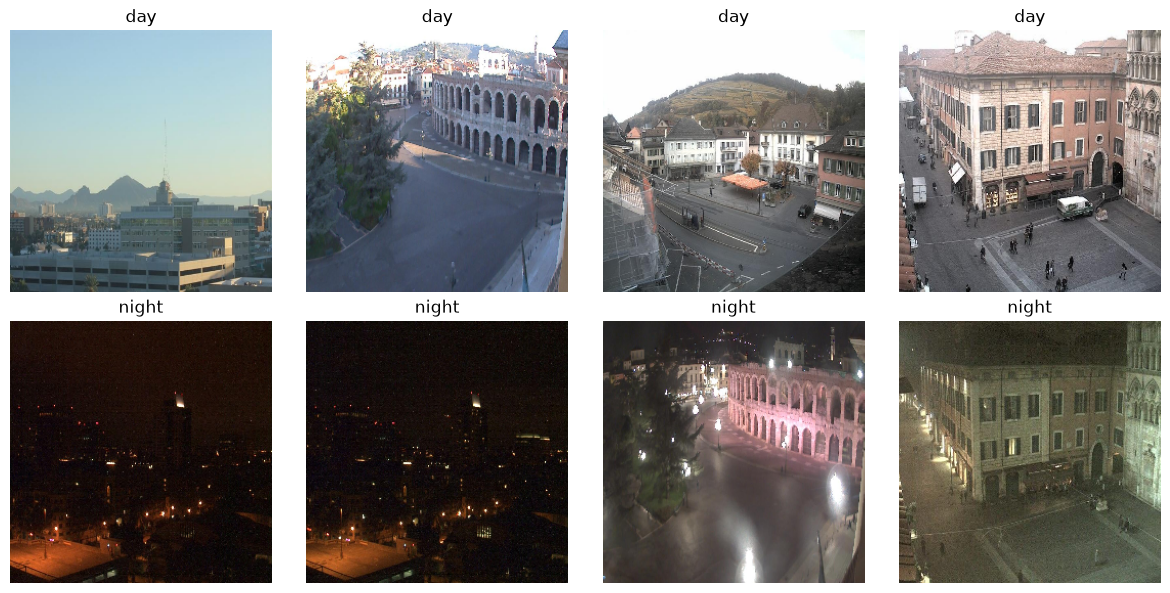

In [ ]:
fig, ax = plt.subplots(2, 4, figsize=(12, 6))
for baris, (kelas, nilai) in enumerate([('day', 1), ('night', 0)]):
    semua = [img for img, label in zip(X_train_img, y_train) if label == nilai]
    posisi = np.linspace(0, len(semua) - 1, 4).astype(int)
    for kolom, idx in enumerate(posisi):
        ax[baris, kolom].imshow(semua[idx])
        ax[baris, kolom].set_title(kelas)
        ax[baris, kolom].axis('off')
plt.tight_layout()
plt.show()

## Langkah 4: Ekstraksi Fitur HOG

HOG menghitung sebaran arah gradien pada sel berukuran 8 x 8 piksel, lalu menggabungkan empat sel bertetangga menjadi satu blok 2 x 2. Dengan citra 256 x 256, 9 orientasi, dan normalisasi L2-Hys, satu citra menghasilkan 34.596 nilai. Jumlah ini jauh lebih kecil daripada 196.608 piksel mentah, sehingga model lebih ringan dan lebih tahan terhadap perbedaan pencahayaan. Pada citra malam, hanya titik terang seperti lampu yang menghasilkan gradien kuat, sedangkan bagian gelap hampir tidak menyumbang nilai.

In [ ]:
# Extract HOG features
def extract_hog(X_imgs):
    feats = []
    for img in X_imgs:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        hog_feat = hog(gray,
                       orientations=9,
                       pixels_per_cell=(8,8),
                       cells_per_block=(2,2),
                       block_norm='L2-Hys',
                       visualize=False,
                       feature_vector=True)
        feats.append(hog_feat)
    return np.array(feats)

X_train_feat = extract_hog(X_train_img)
X_test_feat  = extract_hog(X_test_img)

print('Bentuk fitur latih:', X_train_feat.shape)
print('Bentuk fitur uji  :', X_test_feat.shape)

Bentuk fitur latih: (240, 34596)
Bentuk fitur uji  : (160, 34596)


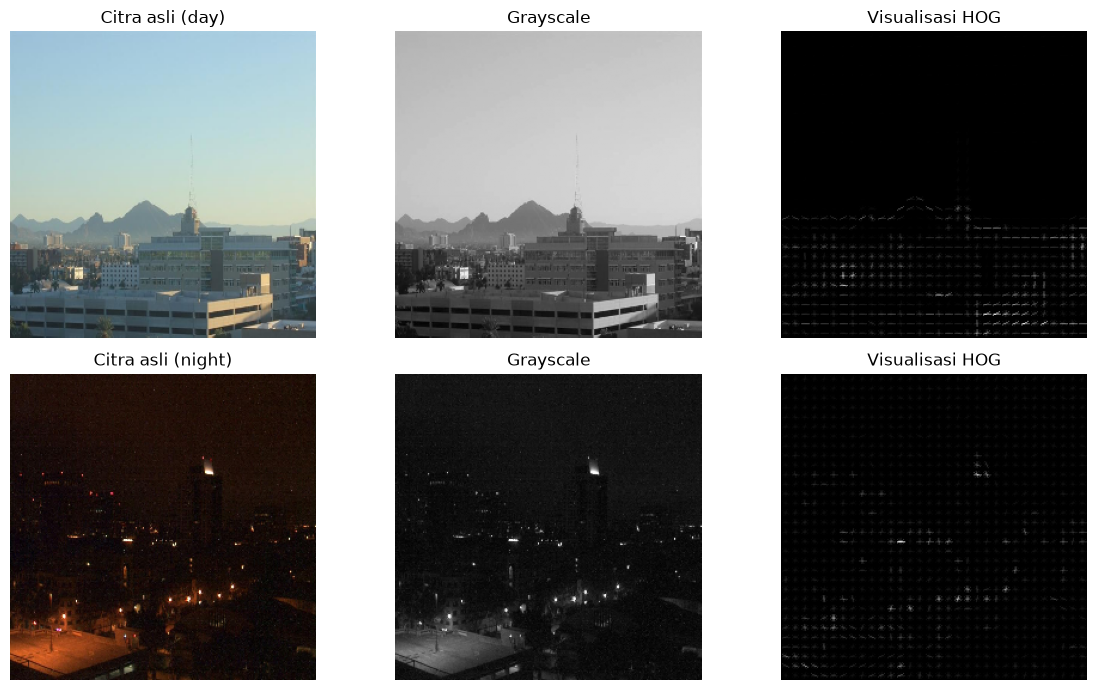

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(12, 7))
for baris, (nama, nilai) in enumerate([('day', 1), ('night', 0)]):
    idx = next(i for i, v in enumerate(y_train) if v == nilai)
    contoh = X_train_img[idx]
    abu = cv2.cvtColor(contoh, cv2.COLOR_RGB2GRAY)
    _, gambar_hog = hog(abu, orientations=9, pixels_per_cell=(8,8),
                        cells_per_block=(2,2), block_norm='L2-Hys',
                        visualize=True, feature_vector=True)

    ax[baris, 0].imshow(contoh); ax[baris, 0].set_title('Citra asli (%s)' % nama)
    ax[baris, 1].imshow(abu, cmap='gray'); ax[baris, 1].set_title('Grayscale')
    ax[baris, 2].imshow(gambar_hog, cmap='gray'); ax[baris, 2].set_title('Visualisasi HOG')
    for a in ax[baris]:
        a.axis('off')
plt.tight_layout()
plt.show()

## Langkah 5: Normalisasi Fitur

Nilai HOG berbeda jauh antar dimensi, ada yang mendekati nol dan ada yang lebih dari 0.2. `StandardScaler` menyetarakan skala dengan mengurangi rata-rata lalu membagi simpangan baku. Scaler hanya di-`fit` pada data latih, sedangkan data uji hanya di-`transform`, supaya tidak ada informasi data uji yang masuk ke proses pelatihan.

In [ ]:
# Normalize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled  = scaler.transform(X_test_feat)

print('Rata-rata sebelum :', round(X_train_feat.mean(), 4))
print('Simpangan sebelum :', round(X_train_feat.std(), 4))
print('Rata-rata sesudah :', round(X_train_scaled.mean(), 4))
print('Simpangan sesudah :', round(X_train_scaled.std(), 4))

Rata-rata sebelum : 0.1339
Simpangan sebelum : 0.0972
Rata-rata sesudah : -0.0
Simpangan sesudah : 1.0


## Langkah 6: Split Data Training dan Validation

Sebanyak 20 persen data latih disisihkan sebagai data validasi untuk memantau apakah model mulai menghafal data latih.

In [ ]:
# Split training data for validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_scaled, y_train,
    test_size=0.2,
    random_state=42
)

print('Data latih    :', X_train.shape)
print('Data validasi :', X_val.shape)

Data latih    : (192, 34596)
Data validasi : (48, 34596)


## Langkah 7: Konversi Label ke Numpy Array

Label masih berupa list Python, sedangkan Keras membutuhkan array NumPy.

In [ ]:
# Convert labels to numpy arrays (required for Keras)
y_train = np.array(y_train)
y_val = np.array(y_val)
y_test = np.array(y_test)

print(y_train.shape, y_val.shape, y_test.shape)
print('Jumlah fitur per citra:', X_train.shape[1])

(192,) (48,) (160,)
Jumlah fitur per citra: 34596


## Langkah 8: Membangun Arsitektur Model Neural Network

Model feedforward dengan dua hidden layer berisi 128 dan 64 neuron dengan aktivasi ReLU, lalu satu neuron output dengan sigmoid. Sigmoid dipakai karena hanya ada dua kelas, dan nilainya dibaca sebagai peluang sebuah citra termasuk kelas day.

In [ ]:
# Build a simple feedforward neural network
# Define model architecture
# input_dim is the number of features in the dataset
# Hidden layer -> 128 neurons, ReLU activation
# Hidden layer -> 64 neurons, ReLU activation
# Output layer -> 1 neuron, Sigmoid activation (for binary classification)
input_dim = X_train.shape[1]

model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     4,428,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

Total params: 4,436,737 (16.92 MB)

Trainable params: 4,436,737 (16.92 MB)

Non-trainable params: 0 (0.00 B)

## Langkah 9: Training Model

Pelatihan 20 epoch dengan batch size 32. Data validasi dipakai untuk melihat performa pada data yang tidak ikut dilatih.

In [ ]:
# Train the model
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val)
)

print()
print('Akurasi latih akhir    :', round(history.history['accuracy'][-1], 4))
print('Akurasi validasi akhir :', round(history.history['val_accuracy'][-1], 4))
print('Loss latih akhir       :', round(history.history['loss'][-1], 4))
print('Loss validasi akhir    :', round(history.history['val_loss'][-1], 4))

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 77ms/step - accuracy: 0.7969 - loss: 0.9021 - val_accuracy: 0.9792 - val_loss: 0.0387
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.9896 - loss: 0.0167 - val_accuracy: 1.0000 - val_loss: 0.0013
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 1.0000 - loss: 0.0015 - val_accuracy: 1.0000 - val_loss: 0.0043
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.9948 - loss: 0.0040 - val_accuracy: 1.0000 - val_loss: 0.0019
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 1.0000 - loss: 3.5133e-07 - val_accuracy: 1.0000 - val_loss: 0.0031
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 1.0000 - loss: 2.9190e-07 - val_accuracy: 1.0000 - val_loss: 0.0035
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 1.0000 - loss: 1.2215e-06 - val_accuracy: 1.0000 - val_loss: 0.0037
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 1.0000 - loss: 1.2491e-05 - val_accuracy: 1.0000 - v

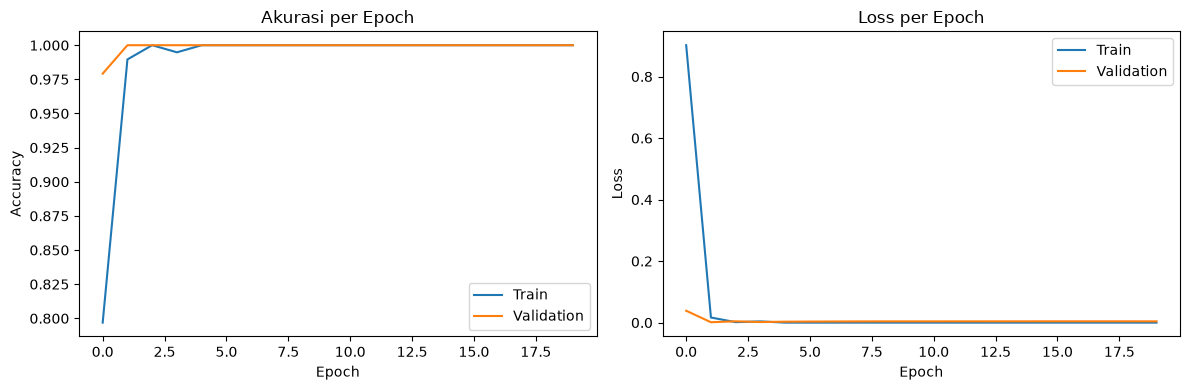

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history['accuracy'], label='Train')
ax[0].plot(history.history['val_accuracy'], label='Validation')
ax[0].set_title('Akurasi per Epoch')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Accuracy')
ax[0].legend()
ax[1].plot(history.history['loss'], label='Train')
ax[1].plot(history.history['val_loss'], label='Validation')
ax[1].set_title('Loss per Epoch')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Loss')
ax[1].legend()
plt.tight_layout()
plt.show()

## Langkah 10: Evaluasi Model

Model diuji pada 160 citra test yang tidak dipakai saat pelatihan maupun validasi.

In [ ]:
# Evaluate the model on test data
test_loss, test_acc = model.evaluate(X_test_scaled, y_test, verbose=0)
print("Akurasi Test:", test_acc)

Akurasi Test: 0.9375


## Langkah 11: Prediksi dan Laporan Klasifikasi

Nilai sigmoid di atas 0.5 dibaca sebagai day dan di bawah 0.5 sebagai night. Selain laporan klasifikasi, ditampilkan confusion matrix dan beberapa citra yang salah diprediksi.

In [ ]:
# Generate classification report and confusion matrix
y_pred_prob = model.predict(X_test_scaled, verbose=0)
y_pred = (y_pred_prob > 0.5).astype(int)

print(classification_report(y_test, y_pred, target_names=['night', 'day']))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

       night       0.91      0.97      0.94        80
         day       0.97      0.90      0.94        80

    accuracy                           0.94       160
   macro avg       0.94      0.94      0.94       160
weighted avg       0.94      0.94      0.94       160

[[78  2]
 [ 8 72]]


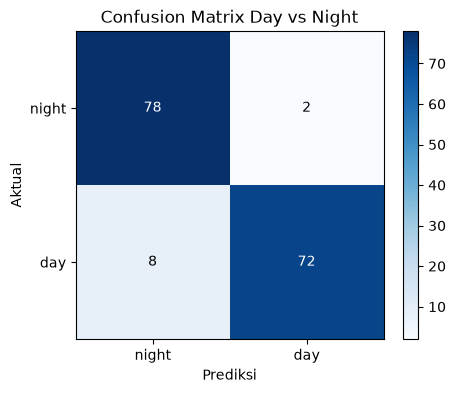

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
plt.imshow(cm, cmap='Blues')
plt.title('Confusion Matrix Day vs Night')
plt.colorbar()
plt.xticks([0, 1], ['night', 'day'])
plt.yticks([0, 1], ['night', 'day'])
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center',
                 color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.show()

Jumlah salah: 10 dari 160


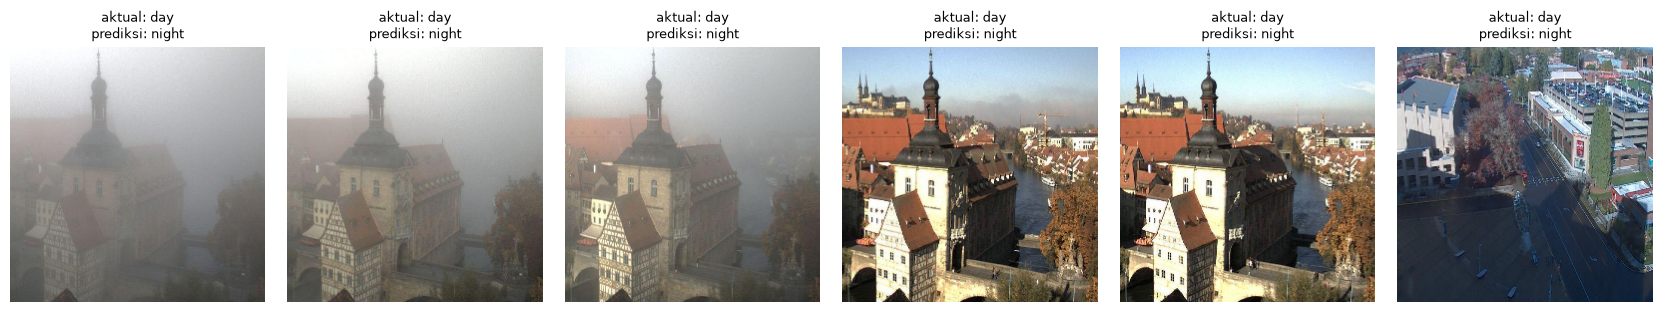

In [ ]:
salah = np.where(y_pred.ravel() != y_test)[0]
print('Jumlah salah:', len(salah), 'dari', len(y_test))

if len(salah):
    n = min(6, len(salah))
    fig, ax = plt.subplots(1, n, figsize=(2.8 * n, 3))
    for i, idx in enumerate(salah[:n]):
        ax[i].imshow(X_test_img[idx])
        ax[i].set_title('aktual: %s\nprediksi: %s' % (
            'day' if y_test[idx] == 1 else 'night',
            'day' if y_pred[idx] == 1 else 'night'), fontsize=9)
        ax[i].axis('off')
    plt.tight_layout()
    plt.show()

## Langkah 12: Menyimpan Model dan Scaler

Dua artefak yang disimpan, yaitu file model `.h5` berisi bobot hasil pelatihan dan `scaler.pkl` berisi rata-rata serta simpangan baku yang dipelajari dari data latih. Keduanya dibutuhkan pada tahap deployment, karena gambar baru harus melewati HOG dan scaler yang sama persis.

In [ ]:
# Save the trained model
import pickle

# 1. Simpan Model
# Menggunakan format .h5
model.save('day_night_model.h5')
print("Model berhasil disimpan sebagai: day_night_model.h5")

# 2. Simpan Scaler
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
print("Scaler berhasil disimpan sebagai: scaler.pkl")

print('Ukuran model  :', round(Path('day_night_model.h5').stat().st_size / 1024, 1), 'KB')
print('Ukuran scaler :', round(Path('scaler.pkl').stat().st_size / 1024, 1), 'KB')

Model berhasil disimpan sebagai: day_night_model.h5
Scaler berhasil disimpan sebagai: scaler.pkl
Ukuran model  : 52024.7 KB
Ukuran scaler : 811.3 KB


Sebelum dipakai untuk deployment, kedua file dimuat ulang lalu dicoba pada beberapa gambar dari folder test. Tujuannya memastikan artefak yang tersimpan benar-benar bisa dipakai di proses terpisah, bukan hanya ada di memori notebook.

In [ ]:
model_muat = tf.keras.models.load_model('day_night_model.h5')
with open('scaler.pkl', 'rb') as f:
    scaler_muat = pickle.load(f)

for folder in ['images/test/day', 'images/test/night']:
    for berkas in sorted(Path(folder).glob('*.jpg'))[:3]:
        img = cv2.cvtColor(cv2.imread(str(berkas)), cv2.COLOR_BGR2RGB)
        img = resize_image(img)
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        fitur = hog(gray, orientations=9, pixels_per_cell=(8,8),
                    cells_per_block=(2,2), block_norm='L2-Hys',
                    visualize=False, feature_vector=True)
        fitur = scaler_muat.transform(fitur.reshape(1, -1))
        skor = model_muat.predict(fitur, verbose=0)[0][0]
        print('%-28s skor day = %.4f  ->  %s' % (
            berkas.name, skor, 'day' if skor > 0.5 else 'night'))

20151101_152050.jpg          skor day = 1.0000  ->  day
20151101_152512.jpg          skor day = 1.0000  ->  day
20151101_165048.jpg          skor day = 1.0000  ->  day
20151101_072507.jpg          skor day = 0.0000  ->  night
20151101_230938.jpg          skor day = 0.0000  ->  night
20151101_231132.jpg          skor day = 0.0000  ->  night


## Pembahasan

Dari 400 citra, 240 dipakai sebagai data latih dan 160 sebagai data uji, dengan komposisi day dan night yang seimbang. Setelah resize ke 256 x 256 dan ekstraksi HOG, satu citra diwakili 34.596 nilai, jauh lebih sedikit daripada 196.608 piksel mentahnya.

Model memiliki 4.436.737 parameter dan hampir semuanya berada di hidden layer pertama, yaitu 4.428.416 parameter atau sekitar 99.8 persen dari total. Penyebabnya setiap neuron di layer itu menerima seluruh 34.596 fitur HOG sebagai masukan. Hidden layer kedua hanya 8.256 parameter dan layer output 65 parameter.

Akurasi data uji 0.9375, artinya 10 dari 160 citra uji salah diklasifikasikan. Pada epoch terakhir akurasi latih mencapai 1.0000 dan akurasi validasi 1.0000. Loss latih sudah turun mendekati nol dan loss validasi hanya 0.0042, jadi model sudah hampir sempurna memisahkan kedua kelas pada data yang tersedia.  Selisih akurasi latih dan uji 0.0625 poin, jadi model masih cukup baik membedakan dua kelas ini meskipun jumlah parameternya jauh melebihi jumlah data latih.

Kelas night punya recall 0.97 dan kelas day 0.90. Dari confusion matrix, 2 citra night diprediksi sebagai day dan 8 citra day diprediksi sebagai night. Kesalahan ke arah night lebih banyak karena citra siang yang diambil saat mendung, berkabut, atau menjelang senja punya gradien yang lemah sehingga mirip citra malam.

Setelah model dan scaler dimuat ulang dari file, keenam citra uji diprediksi dengan benar. Skor yang keluar sangat ekstrem, mendekati 0 atau 1, bukan nilai di sekitar 0.5. Ini tanda lain bahwa model terlalu percaya diri pada data yang mirip data latih.

# Praktikum 2 - Deployment ke Hugging Face (Docker dan Flask)

Model yang sudah dilatih belum bisa dipakai orang lain. Pada praktikum ini model dibungkus menjadi aplikasi Flask, dimasukkan ke container Docker, lalu dikirim ke Hugging Face Spaces lewat Git. Aplikasinya diuji dulu secara lokal sebelum dikirim, supaya kesalahan pemuatan model atau preprocessing bisa diketahui lebih awal.

## Langkah 1: Persiapan Environment

Folder `daynight-project` dibuat sebagai folder proyek. Dua artefak dari Praktikum 1 disalin ke dalamnya, karena `app.py` membaca model dan scaler dari folder yang sama dengan lokasi file aplikasinya.

In [ ]:
import shutil

proyek = Path('daynight-project')
proyek.mkdir(exist_ok=True)

for berkas in ['day_night_model.h5', 'scaler.pkl']:
    shutil.copy(berkas, proyek / berkas)

for berkas in sorted(proyek.iterdir()):
    print('%-24s %8.1f KB' % (berkas.name, berkas.stat().st_size / 1024))

day_night_model.h5        52024.7 KB
scaler.pkl                  811.3 KB


## Langkah 2: Konfigurasi Server (app.py)

`app.py` memuat model dan scaler sekali saat server dinyalakan, lalu menyediakan dua rute: halaman unggah pada `/` dan proses prediksi pada `/predict`. Fungsi `preprocess_image` memakai urutan yang sama dengan saat training, yaitu resize 256 x 256, konversi ke grayscale, HOG dengan parameter identik, lalu `scaler.transform`.

In [ ]:
%%writefile daynight-project/app.py
import os
import numpy as np
import cv2
import pickle
import tensorflow as tf
from flask import Flask, request, render_template_string
from skimage.feature import hog

app = Flask(__name__)

# Load Model & Scaler
MODEL_PATH = 'day_night_model.h5'
SCALER_PATH = 'scaler.pkl'

try:
    model = tf.keras.models.load_model(MODEL_PATH)
    with open(SCALER_PATH, 'rb') as f:
        scaler = pickle.load(f)
    print("System Loaded Successfully")
except Exception as e:
    print(f"Error loading system: {e}")

def preprocess_image(image_bytes):
    # Decode gambar
    nparr = np.frombuffer(image_bytes, np.uint8)
    img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)

    # Preprocessing (Harus sama persis dengan Training)
    img = cv2.resize(img, (256, 256))
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    hog_feat = hog(gray, orientations=9, pixels_per_cell=(8,8),
                   cells_per_block=(2,2), block_norm='L2-Hys',
                   visualize=False, feature_vector=True)

    return scaler.transform(hog_feat.reshape(1, -1))

@app.route('/', methods=['GET'])
def home():
    return render_template_string('''
    <div style="text-align:center; padding:50px;">
        <h1>Day vs Night Classifier</h1>
        <form action="/predict" method="post" enctype="multipart/form-data">
            <input type="file" name="file" required><br><br>
            <button type="submit">Prediksi</button>
        </form>
    </div>
    ''')

@app.route('/predict', methods=['POST'])
def predict():
    try:
        file = request.files['file']
        data = preprocess_image(file.read())
        prediction = model.predict(data)[0][0]

        label = "Day (Siang)" if prediction > 0.5 else "Night (Malam)"
        return f"<h2 style='text-align:center'>Hasil: {label}</h2><center><a href='/'>Kembali</a></center>"
    except Exception as e:
        return f"Error: {e}"

if __name__ == '__main__':
    # Port 7860 wajib untuk Hugging Face Spaces
    app.run(host='0.0.0.0', port=7860)

Writing daynight-project/app.py


## Langkah 3: Konfigurasi Dependencies (requirements.txt)

Daftar library yang dipasang di dalam container. `tensorflow-cpu` dipakai karena server Spaces berjalan tanpa GPU, sedangkan `opencv-python-headless` dipilih karena container tidak punya tampilan grafis.

In [ ]:
%%writefile daynight-project/requirements.txt
flask
tensorflow-cpu
numpy
scikit-learn
scikit-image
opencv-python-headless
gunicorn

Writing daynight-project/requirements.txt


## Langkah 4: Konfigurasi Docker (Dockerfile)

Base image `python:3.9-slim` dipakai agar image tidak terlalu besar. `libgl1` dan `libglib2.0-0` dipasang karena OpenCV membutuhkannya, user non-root dibuat sesuai standar Hugging Face, lalu aplikasi dijalankan pada port 7860.

In [ ]:
%%writefile daynight-project/Dockerfile
# Base Image Python 3.9 Slim
FROM python:3.9-slim

# Install Library Sistem untuk OpenCV (Debian Bookworm/Trixie Compatible)
RUN apt-get update && apt-get install -y \
    libgl1 \
    libglib2.0-0 \
    && rm -rf /var/lib/apt/lists/*

# Setup User Non-Root (Standar Keamanan HF)
RUN useradd -m -u 1000 user
USER user
ENV PATH="/home/user/.local/bin:$PATH"

# Setup Direktori Kerja
WORKDIR /app

# Install Dependencies
COPY --chown=user ./requirements.txt requirements.txt
RUN pip install --no-cache-dir --upgrade -r requirements.txt

# Copy File Aplikasi
COPY --chown=user . /app

# Expose Port & Jalankan
EXPOSE 7860
CMD ["python", "app.py"]

Writing daynight-project/Dockerfile


In [ ]:
for nama in ['app.py', 'requirements.txt', 'Dockerfile']:
    print('=' * 24, nama, '=' * 24)
    print((proyek / nama).read_text(encoding='utf-8'))

======================== app.py ========================
import os
import numpy as np
import cv2
import pickle
import tensorflow as tf
from flask import Flask, request, render_template_string
from skimage.feature import hog

app = Flask(__name__)

# Load Model & Scaler
MODEL_PATH = 'day_night_model.h5'
SCALER_PATH = 'scaler.pkl'

try:
    model = tf.keras.models.load_model(MODEL_PATH)
    with open(SCALER_PATH, 'rb') as f:
        scaler = pickle.load(f)
    print("System Loaded Successfully")
except Exception as e:
    print(f"Error loading system: {e}")

def preprocess_image(image_bytes):
    # Decode gambar
    nparr = np.frombuffer(image_bytes, np.uint8)
    img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)

    # Preprocessing (Harus sama persis dengan Training)
    img = cv2.resize(img, (256, 256))
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    hog_feat = hog(gray, orientations=9, pixels_per_cell=(8,8),
                   cells_per_block=(2,2), block_norm='L2-Hys',
             

## Langkah 5: Setup Hugging Face Space

Space dibuat lewat web, bukan lewat kode. Setelah login, pilih menu New Space lalu isi nama `daynight-classifier-244107020198`, lisensi MIT, SDK Docker, template kosong, dan visibility Public. Setelah Space terbentuk, token akses dibuat di Settings > Access Tokens dengan permission Write. Token ini nanti dipakai sebagai password Git, bukan password akun.

## Langkah 6: Upload ke Cloud

Repository kosong di-clone ke komputer, kelima file disalin ke dalamnya, lalu di-commit dan di-push. Perintah yang dijalankan pada terminal:

```bash
git clone https://huggingface.co/spaces/USERNAME_ANDA/daynight-classifier-244107020198
cd daynight-classifier-244107020198
cp ../daynight-project/* .
git add .
git commit -m "Deploy aplikasi ke HF"
git push
```

Saat `git push` meminta kredensial, username diisi nama akun Hugging Face dan password diisi token dengan permission Write. Setelah push selesai, status Space berubah dari Building menjadi Running dalam beberapa menit, dan aplikasi bisa dipakai lewat tab App.

## Langkah 7: Pengujian Lokal

Sebelum dikirim ke Spaces, aplikasi dijalankan dulu pada port 7860 dan diuji dengan beberapa citra test. Cara ini sama dengan yang dijalankan Spaces, hanya saja servernya berada di komputer sendiri. Fungsi bantu di bawah memuat `app.py` dari folder proyek lalu menjalankannya pada thread terpisah.

In [ ]:
import os
import re
import time
import threading
import importlib.util

import requests
from werkzeug.serving import make_server


def jalankan_aplikasi(folder, port):
    folder = Path(folder).resolve()
    berkas_app = folder / 'app.py'
    spesifikasi = importlib.util.spec_from_file_location(
        'app_' + folder.name, berkas_app)
    modul = importlib.util.module_from_spec(spesifikasi)
    os.chdir(folder)
    spesifikasi.loader.exec_module(modul)
    os.chdir(folder.parent)

    server = make_server('127.0.0.1', port, modul.app)
    threading.Thread(target=server.serve_forever, daemon=True).start()
    time.sleep(1)
    return server


def kirim_citra(port, jalur):
    mulai = time.perf_counter()
    with open(jalur, 'rb') as f:
        respons = requests.post(f'http://127.0.0.1:{port}/predict',
                                files={'file': (jalur.name, f, 'image/jpeg')},
                                timeout=60)
    return respons, time.perf_counter() - mulai

In [ ]:
server_daynight = jalankan_aplikasi('daynight-project', 7860)

halaman = requests.get('http://127.0.0.1:7860/', timeout=30)
print('GET /          :', halaman.status_code)
print('Halaman unggah :', 'Day vs Night Classifier' in halaman.text)

System Loaded Successfully
GET /          : 200
Halaman unggah : True


In [ ]:
hasil = []

for folder in ['images/test/day', 'images/test/night']:
    for jalur in sorted(Path(folder).glob('*.jpg'))[:3]:
        respons, jeda = kirim_citra(7860, jalur)
        label = re.search(r'Hasil: ([^<]+)</h2>', respons.text).group(1).strip()
        hasil.append((jalur, label, jeda))
        print('%-5s %-28s -> %-14s %6.0f ms' % (
            jalur.parent.name, jalur.name, label, jeda * 1000))

cocok = sum(1 for jalur, label, _ in hasil
            if label.lower().startswith(jalur.parent.name))
print()
print('Prediksi cocok dengan folder asal: %d dari %d' % (cocok, len(hasil)))

day   20151101_152050.jpg          -> Day (Siang)       155 ms
day   20151101_152512.jpg          -> Day (Siang)       156 ms
day   20151101_165048.jpg          -> Day (Siang)       117 ms
night 20151101_072507.jpg          -> Night (Malam)     137 ms
night 20151101_230938.jpg          -> Night (Malam)     123 ms
night 20151101_231132.jpg          -> Night (Malam)     114 ms

Prediksi cocok dengan folder asal: 6 dari 6


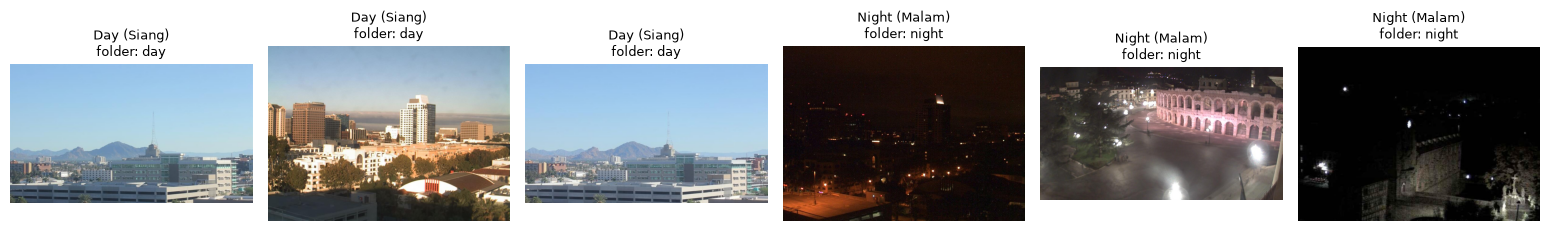

In [ ]:
fig, ax = plt.subplots(1, len(hasil), figsize=(2.6 * len(hasil), 3))
for i, (jalur, label, _) in enumerate(hasil):
    ax[i].imshow(cv2.cvtColor(cv2.imread(str(jalur)), cv2.COLOR_BGR2RGB))
    ax[i].set_title('%s\nfolder: %s' % (label, jalur.parent.name), fontsize=9)
    ax[i].axis('off')
plt.tight_layout()
plt.show()

server_daynight.shutdown()
server_daynight.server_close()

## Pembahasan

Aplikasi Flask berjalan pada port 7860 dan melayani halaman unggah dengan status 200. Enam citra uji dikirim lewat `POST /predict` dan keenamnya kembali dengan label yang sesuai folder asalnya. Waktu respons berkisar 114 sampai 156 milidetik, sudah termasuk pemrosesan HOG dan prediksi model.

Yang paling menentukan pada tahap ini adalah kesamaan preprocessing. `app.py` memakai resize 256 x 256, konversi BGR ke grayscale, HOG dengan orientasi 9, sel 8 x 8, blok 2 x 2, dan normalisasi L2-Hys, lalu `scaler.transform`. Urutan ini sama dengan saat pelatihan. Kalau salah satu parameter diubah, jumlah fitur tidak lagi 34.596 dan model akan menolak masukan tersebut.

Dockerfile memakai `python:3.9-slim` sebagai base image, memasang `libgl1` dan `libglib2.0-0` untuk OpenCV, membuat user non-root sesuai standar Hugging Face, lalu menjalankan `python app.py` pada port 7860. Port itu wajib karena Spaces mengarahkan trafik ke port tersebut.

Ukuran image nanti akan didominasi `tensorflow-cpu`, bukan kode aplikasi. Kode `app.py` hanya sekitar 2 KB, sedangkan modelnya 52.025 KB dan scaler 811 KB, jadi wajar bila proses build di Spaces memakan beberapa menit.

# Tugas - Deployment Model Project Sendiri

Pipeline yang sama diterapkan pada model project sendiri. Dataset yang dipakai adalah Cat vs Dog dari JS14, berisi 8.000 citra latih dan 2.000 citra test. Karena HOG 256 x 256 menghasilkan 34.596 fitur per citra, dipakai subset berimbang 2.400 citra latih dan 600 citra test supaya prosesnya tetap ringan. Langkahnya sama seperti Praktikum 1, yaitu resize, grayscale, HOG, StandardScaler, split validasi, lalu Neural Network.

## Langkah 1: Menyiapkan Data dan Artefak Model

Folder dataset diekstrak kalau belum ada, lalu citra dibaca per kelas. Label `cat` menjadi 0 dan `dog` menjadi 1.

In [ ]:
if not Path('dataset/training_set').exists():
    with zipfile.ZipFile('dataset.zip') as z:
        for anggota in z.namelist():
            if anggota.startswith('__MACOSX') or anggota.endswith('/'):
                continue
            z.extract(anggota, '.')


def ambil_citra(folder, jumlah):
    hasil = []
    for berkas in sorted(Path(folder).glob('*.jpg'))[:jumlah]:
        img = cv2.imread(str(berkas))
        hasil.append(resize_image(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)))
    return hasil


latih_kucing = ambil_citra('dataset/training_set/cats', 1200)
latih_anjing = ambil_citra('dataset/training_set/dogs', 1200)
uji_kucing   = ambil_citra('dataset/test_set/cats', 300)
uji_anjing   = ambil_citra('dataset/test_set/dogs', 300)

X_proj_train = latih_kucing + latih_anjing
y_proj_train = [0] * len(latih_kucing) + [1] * len(latih_anjing)
X_proj_test  = uji_kucing + uji_anjing
y_proj_test  = [0] * len(uji_kucing) + [1] * len(uji_anjing)

print('Citra latih :', len(X_proj_train))
print('Citra uji   :', len(X_proj_test))
print('Sebaran latih:', np.bincount(y_proj_train))
print('Sebaran uji  :', np.bincount(y_proj_test))

Citra latih : 2400
Citra uji   : 600
Sebaran latih: [1200 1200]
Sebaran uji  : [300 300]


In [ ]:
X_proj_train_feat = extract_hog(X_proj_train)
X_proj_test_feat  = extract_hog(X_proj_test)

print('Bentuk fitur latih:', X_proj_train_feat.shape)
print('Bentuk fitur uji  :', X_proj_test_feat.shape)

Bentuk fitur latih: (2400, 34596)
Bentuk fitur uji  : (600, 34596)


In [ ]:
scaler_proj = StandardScaler()
X_proj_train_scaled = scaler_proj.fit_transform(X_proj_train_feat)
X_proj_test_scaled  = scaler_proj.transform(X_proj_test_feat)

Xp_train, Xp_val, yp_train, yp_val = train_test_split(
    X_proj_train_scaled, y_proj_train,
    test_size=0.2,
    random_state=42
)

yp_train = np.array(yp_train)
yp_val = np.array(yp_val)
y_proj_test = np.array(y_proj_test)

print('Latih    :', Xp_train.shape)
print('Validasi :', Xp_val.shape)
print('Uji      :', X_proj_test_scaled.shape)

Latih    : (1920, 34596)
Validasi : (480, 34596)
Uji      : (600, 34596)


## Langkah 2: Melatih Model Project

Arsitektur dan konfigurasi pelatihan dibuat sama dengan Praktikum 1 supaya perbandingannya adil. Yang berbeda hanya jumlah fitur masukan, sedangkan jumlah kelasnya tetap dua.

In [ ]:
model_proj = models.Sequential([
    layers.Input(shape=(Xp_train.shape[1],)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model_proj.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history_proj = model_proj.fit(
    Xp_train, yp_train,
    epochs=20,
    batch_size=32,
    validation_data=(Xp_val, yp_val)
)

print()
print('Akurasi latih akhir    :', round(history_proj.history['accuracy'][-1], 4))
print('Akurasi validasi akhir :', round(history_proj.history['val_accuracy'][-1], 4))
print('Loss latih akhir       :', round(history_proj.history['loss'][-1], 4))
print('Loss validasi akhir    :', round(history_proj.history['val_loss'][-1], 4))

Epoch 1/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - accuracy: 0.6573 - loss: 1.2132 - val_accuracy: 0.6896 - val_loss: 0.9427
Epoch 2/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.9333 - loss: 0.2263 - val_accuracy: 0.7167 - val_loss: 1.1459
Epoch 3/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.9849 - loss: 0.0448 - val_accuracy: 0.7208 - val_loss: 1.2777
Epoch 4/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.9979 - loss: 0.0078 - val_accuracy: 0.7250 - val_loss: 1.2315
Epoch 5/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.9990 - loss: 0.0120 - val_accuracy: 0.7125 - val_loss: 1.2714
Epoch 6/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.9990 - loss: 0.0170 - val_accuracy: 0.7229 - val_loss: 1.2669
Epoch 7/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 1.0000 - loss: 6.3967e-04 - val_accuracy: 0.7333 - val_loss: 1.2983
Epoch 8/20
60/60 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 1.0000 - loss: 2.4343e-04 - val_accuracy: 0.

In [ ]:
loss_proj, acc_proj = model_proj.evaluate(X_proj_test_scaled, y_proj_test, verbose=0)
print('Loss data uji    :', round(loss_proj, 4))
print('Akurasi data uji :', round(acc_proj, 4))
print()

y_proj_pred = (model_proj.predict(X_proj_test_scaled, verbose=0) > 0.5).astype(int)
print(classification_report(y_proj_test, y_proj_pred,
                            target_names=['cat', 'dog']))
print(confusion_matrix(y_proj_test, y_proj_pred))

Loss data uji    : 1.4137
Akurasi data uji : 0.6967

              precision    recall  f1-score   support

         cat       0.72      0.64      0.68       300
         dog       0.68      0.76      0.71       300

    accuracy                           0.70       600
   macro avg       0.70      0.70      0.70       600
weighted avg       0.70      0.70      0.70       600

[[191 109]
 [ 73 227]]


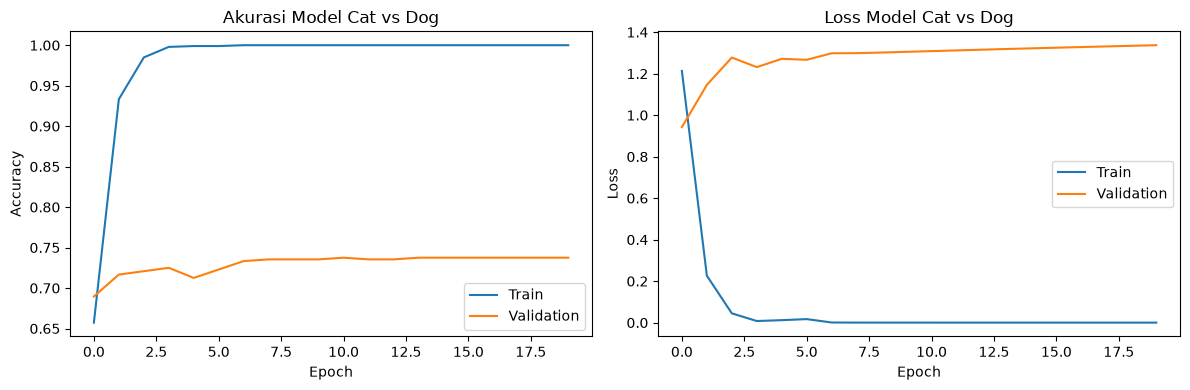

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history_proj.history['accuracy'], label='Train')
ax[0].plot(history_proj.history['val_accuracy'], label='Validation')
ax[0].set_title('Akurasi Model Cat vs Dog')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Accuracy')
ax[0].legend()
ax[1].plot(history_proj.history['loss'], label='Train')
ax[1].plot(history_proj.history['val_loss'], label='Validation')
ax[1].set_title('Loss Model Cat vs Dog')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Loss')
ax[1].legend()
plt.tight_layout()
plt.show()

## Langkah 3: Menyimpan Artefak

Sama seperti Praktikum 1, model disimpan ke `.h5` dan scaler ke `.pkl`, lalu disalin ke folder proyek.

In [ ]:
model_proj.save('catdog_model.h5')
with open('catdog_scaler.pkl', 'wb') as f:
    pickle.dump(scaler_proj, f)

proyek_tugas = Path('catdog-project')
proyek_tugas.mkdir(exist_ok=True)
for berkas in ['catdog_model.h5', 'catdog_scaler.pkl']:
    shutil.copy(berkas, proyek_tugas / berkas)

for berkas in sorted(proyek_tugas.iterdir()):
    print('%-24s %8.1f KB' % (berkas.name, berkas.stat().st_size / 1024))

catdog_model.h5           52025.1 KB
catdog_scaler.pkl           811.3 KB


## Langkah 4: Konfigurasi app.py dan Docker

Strukturnya sama dengan `app.py` pada Praktikum 2, yang berbeda hanya nama file model, nama file scaler, dan teks label hasil. Preprocessing tetap resize 256 x 256, grayscale, HOG, lalu scaler.

In [ ]:
%%writefile catdog-project/app.py
import os
import numpy as np
import cv2
import pickle
import tensorflow as tf
from flask import Flask, request, render_template_string
from skimage.feature import hog

app = Flask(__name__)

# Load Model & Scaler
MODEL_PATH = 'catdog_model.h5'
SCALER_PATH = 'catdog_scaler.pkl'

try:
    model = tf.keras.models.load_model(MODEL_PATH)
    with open(SCALER_PATH, 'rb') as f:
        scaler = pickle.load(f)
    print("System Loaded Successfully")
except Exception as e:
    print(f"Error loading system: {e}")

def preprocess_image(image_bytes):
    nparr = np.frombuffer(image_bytes, np.uint8)
    img = cv2.imdecode(nparr, cv2.IMREAD_COLOR)

    img = cv2.resize(img, (256, 256))
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    hog_feat = hog(gray, orientations=9, pixels_per_cell=(8,8),
                   cells_per_block=(2,2), block_norm='L2-Hys',
                   visualize=False, feature_vector=True)

    return scaler.transform(hog_feat.reshape(1, -1))

@app.route('/', methods=['GET'])
def home():
    return render_template_string('''
    <div style="text-align:center; padding:50px;">
        <h1>Cat vs Dog Classifier</h1>
        <form action="/predict" method="post" enctype="multipart/form-data">
            <input type="file" name="file" required><br><br>
            <button type="submit">Prediksi</button>
        </form>
    </div>
    ''')

@app.route('/predict', methods=['POST'])
def predict():
    try:
        file = request.files['file']
        data = preprocess_image(file.read())
        prediction = model.predict(data)[0][0]

        label = "Dog (Anjing)" if prediction > 0.5 else "Cat (Kucing)"
        return f"<h2 style='text-align:center'>Hasil: {label}</h2><center><a href='/'>Kembali</a></center>"
    except Exception as e:
        return f"Error: {e}"

if __name__ == '__main__':
    # Port 7860 wajib untuk Hugging Face Spaces
    app.run(host='0.0.0.0', port=7860)

Writing catdog-project/app.py


In [ ]:
%%writefile catdog-project/requirements.txt
flask
tensorflow-cpu
numpy
scikit-learn
scikit-image
opencv-python-headless
gunicorn

Writing catdog-project/requirements.txt


In [ ]:
%%writefile catdog-project/Dockerfile
# Base Image Python 3.9 Slim
FROM python:3.9-slim

# Install Library Sistem untuk OpenCV
RUN apt-get update && apt-get install -y \
    libgl1 \
    libglib2.0-0 \
    && rm -rf /var/lib/apt/lists/*

# Setup User Non-Root (Standar Keamanan HF)
RUN useradd -m -u 1000 user
USER user
ENV PATH="/home/user/.local/bin:$PATH"

# Setup Direktori Kerja
WORKDIR /app

# Install Dependencies
COPY --chown=user ./requirements.txt requirements.txt
RUN pip install --no-cache-dir --upgrade -r requirements.txt

# Copy File Aplikasi
COPY --chown=user . /app

# Expose Port & Jalankan
EXPOSE 7860
CMD ["python", "app.py"]

Writing catdog-project/Dockerfile


## Langkah 5: Pengujian Lokal Model Project

Server dijalankan pada port 7861 supaya tidak bertabrakan dengan server Praktikum 2 yang baru dimatikan, sedangkan di dalam container tetap memakai port 7860.

In [ ]:
server_catdog = jalankan_aplikasi('catdog-project', 7861)

halaman_tugas = requests.get('http://127.0.0.1:7861/', timeout=30)
print('GET /          :', halaman_tugas.status_code)
print('Halaman unggah :', 'Cat vs Dog Classifier' in halaman_tugas.text)
print()

# Tiga citra terakhir tiap kelas tidak masuk subset evaluasi di atas
hasil_tugas = []
for folder in ['dataset/test_set/cats', 'dataset/test_set/dogs']:
    for jalur in sorted(Path(folder).glob('*.jpg'))[295:298]:
        respons, jeda = kirim_citra(7861, jalur)
        label = re.search(r'Hasil: ([^<]+)</h2>', respons.text).group(1).strip()
        hasil_tugas.append((jalur, label, jeda))
        print('%-5s %-28s -> %-14s %6.0f ms' % (
            jalur.parent.name, jalur.name, label, jeda * 1000))

cocok_tugas = sum(1 for jalur, label, _ in hasil_tugas
                  if label.lower().startswith(jalur.parent.name.rstrip('s')))
print()
print('Prediksi cocok dengan folder asal: %d dari %d' % (
    cocok_tugas, len(hasil_tugas)))

System Loaded Successfully
GET /          : 200
Halaman unggah : True

cats  cat.4296.jpg                 -> Dog (Anjing)      148 ms
cats  cat.4297.jpg                 -> Cat (Kucing)      119 ms
cats  cat.4298.jpg                 -> Dog (Anjing)      151 ms
dogs  dog.4296.jpg                 -> Dog (Anjing)      117 ms
dogs  dog.4297.jpg                 -> Cat (Kucing)      118 ms
dogs  dog.4298.jpg                 -> Dog (Anjing)      120 ms

Prediksi cocok dengan folder asal: 3 dari 6


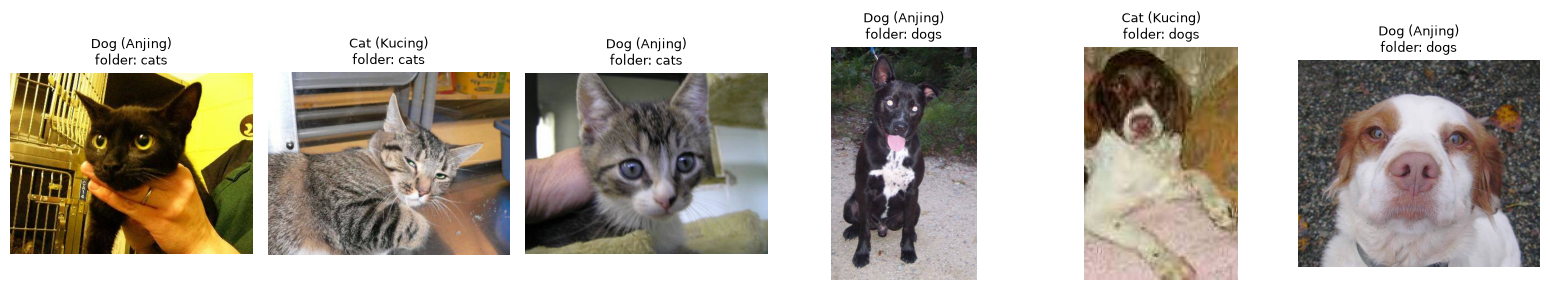

In [ ]:
fig, ax = plt.subplots(1, len(hasil_tugas), figsize=(2.6 * len(hasil_tugas), 3))
for i, (jalur, label, _) in enumerate(hasil_tugas):
    ax[i].imshow(cv2.cvtColor(cv2.imread(str(jalur)), cv2.COLOR_BGR2RGB))
    ax[i].set_title('%s\nfolder: %s' % (label, jalur.parent.name), fontsize=9)
    ax[i].axis('off')
plt.tight_layout()
plt.show()

server_catdog.shutdown()
server_catdog.server_close()

## Langkah 6: Deploy ke Hugging Face

Langkahnya sama seperti Praktikum 2, hanya nama Space dan isi folder yang berbeda. Nama Space yang dipakai `catdog-classifier-244107020198`, lalu perintah git dijalankan pada folder hasil clone:

```bash
git clone https://huggingface.co/spaces/USERNAME_ANDA/catdog-classifier-244107020198
cd catdog-classifier-244107020198
cp ../catdog-project/* .
git add .
git commit -m "Deploy model cat vs dog"
git push
```

## Pembahasan

Pipeline yang dipakai sama persis dengan Praktikum 1, hanya dataset dan nama artefaknya yang berbeda. Sebanyak 2.400 citra latih dan 600 citra uji dari dataset Cat vs Dog diubah ke HOG, dinormalisasi dengan scaler baru, lalu dilatih dengan arsitektur 128, 64, dan 1 neuron.

Akurasi data uji 0.6967 dengan loss 1.4137. Angka ini jauh di bawah Praktikum 1. Pada data latih akurasi mencapai 1.0000 dan validasi 0.7375, jadi model menghafal data latih dan gagal menggeneralisasi. Penyebab utamanya dua hal. Pertama, HOG merangkum arah gradien sehingga bentuk tubuh masih terbaca, tetapi tekstur bulu dan warna yang membedakan kucing dan anjing banyak hilang. Kedua, perbedaan day dan night didominasi tingkat kecerahan yang sangat jelas, sedangkan kucing dan anjing sama-sama punya latar rumput, sofa, atau halaman.

Sebagai pembanding, CNN pada JS14 mendapat akurasi 0.8045 pada citra 64 x 64. CNN membaca piksel berwarna secara langsung sehingga tekstur dan warna ikut dipelajari, sementara pipeline HOG di sini membuang informasi warna sejak tahap grayscale.

Dari confusion matrix, 109 citra cat diprediksi dog dan 73 citra dog diprediksi cat, jadi kesalahan lebih banyak pada kelas cat. Recall cat 0.64, sedangkan recall dog 0.76. Pada pengujian lewat server, 3 dari 6 citra mendapat label yang sesuai. Hasil ini cukup untuk menunjukkan bahwa pipeline deployment berjalan, tetapi belum cukup baik sebagai model produksi.

Artefak yang dihasilkan adalah `catdog_model.h5` sebesar 52.025 KB dan `catdog_scaler.pkl`. Keduanya dipakai oleh `app.py` versi kedua pada port 7861 saat pengujian lokal, sedangkan di dalam container tetap port 7860.

# Kesimpulan

Pipeline klasifikasi gambar terdiri dari empat tahap yang harus konsisten antara saat pelatihan dan saat inference, yaitu resize, grayscale, HOG, dan StandardScaler. Kalau salah satu parameter berbeda, misalnya ukuran resize atau jumlah orientasi HOG, jumlah fitur ikut berubah dan model tidak bisa memproses masukan tersebut.

Parameter scaler yang dipelajari dari data latih harus disimpan karena data baru wajib diperlakukan dengan rata-rata dan simpangan baku yang sama. Tanpa `scaler.pkl`, fitur HOG gambar baru berada pada skala berbeda dan prediksi menjadi tidak akurat.

Deployment memisahkan model dari aplikasi. Flask menerima unggahan gambar dan mengembalikan hasil prediksi, Docker membungkus kode beserta library sistem dan library Python, sedangkan Hugging Face Spaces menyediakan server yang bisa diakses publik. Kombinasi ini membuat model bisa dipakai tanpa pengguna perlu memasang Python atau TensorFlow.

## Hasil Akhir

| Model | Artefak | Ukuran | Akurasi uji |
|---|---|---|---|
| Day vs Night (Praktikum 1) | `day_night_model.h5` | 52.025 KB | 0.9375 |
| Cat vs Dog (Tugas) | `catdog_model.h5` | 52.025 KB | 0.6967 |

Kedua model memakai pipeline yang sama, yaitu resize 256 x 256, grayscale, HOG, StandardScaler, lalu Neural Network 128 dan 64 neuron. Yang membedakan hanya isi dataset, sehingga selisih akurasi di tabel di atas berasal dari kecocokan HOG terhadap jenis citranya, bukan dari perbedaan arsitektur.